## 线性回归

本实验主要介绍使用MindSpore在模拟数据上进行线性回归实验，分析自变量和因变量之间的线性关系，即求得一个线性函数。

## 1、实验目的

- 了解线性回归的基本概念和问题模拟；
- 了解如何使用MindSpore进行线性回归实验。

## 2、简单线性回归模型原理

线性回归假设是指预测值可以表示为输入特征的加权和，如下面的式子：

$$ \hat y  = \sum_{i=1}^{n}{w_{i} * x_{i}} + b$$

式中的$n$表示输入特征个数，$i$表示具体的某个特征；$w_{i}$
称为对应特征的权重（weight），权重决定了每个特征对预测值的影响。 
$b$称为偏置（bias）、偏移量（offset）或截距（intercept）。偏置是指当所有特征都取值为0时，预测值应该为多少。式中$\hat y$是输入特征的一个仿射变换（affine transformation）。仿射变换的特点是通过加权和对特征进行线性变换（linear transformation）， 并通过偏置项来进行平移（translation）。

总之，给定一个数据集，线性回归模型的最终目的是为了寻找模型的一组权重$w$和偏置$b$， 使得模型预测大体符合数据的整体变化趋势。即输出的预测值由输入特征通过线性模型的仿射变换决定，仿射变换由所选权重和偏置确定。

## 3、实验环境

- MindSpore 2.0（MindSpore版本会定期更新，本指导也会定期刷新，与版本配套）；
- 本案例支持win_x86和Linux系统，CPU/GPU/Ascend均可运行。
- 如果在本地运行此实验，请参考《MindSpore环境搭建实验手册》在本地安装MindSpore。

## 4、数据处理

### 4.1、数据准备

###### 模块导入：

在生成数据之前，导入需要的Python库。

目前使用到os库，为方便理解，其他需要的库，我们在具体使用到时再说明。

详细的MindSpore的模块说明，可以在MindSpore API页面中搜索查询。

可以通过context.set_context来配置运行需要的信息，譬如运行模式、后端信息、硬件等信息。

导入context模块，配置运行需要的信息。

In [1]:
# 环境检查：确认当前内核使用的是已配置好的 MindSpore 环境
import mindspore as ms

print("MindSpore version:", ms.__version__)
ms.run_check()


MindSpore version: 2.2.0
MindSpore version:  2.2.0
The result of multiplication calculation is correct, MindSpore has been installed on platform [CPU] successfully!


In [2]:
import os
from PIL import Image, ImageDraw
import numpy as np
import mindspore as ms
from mindspore import nn, Tensor, ops
from mindspore.dataset import transforms, vision, GeneratorDataset

np.random.seed(42)
ms.set_seed(42)
ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")      # 使用本地CPU算力
print("Running on CPU with fixed random seed 42")


Running on CPU with fixed random seed 42


### 4.2、数据生成与加载
根据以下线性函数生成模拟数据，并在其中加入少许扰动（$noise$）。

$$y = -5 * x + 0.1 * noise$$

In [3]:
# Iterable object as input source
class Iterable:
    def __init__(self, noise_scale=20.0, seed=42):
        self.noise_scale = noise_scale
        self.seed = seed
        self._data = np.arange(-5, 5, 0.3)[:32].reshape((32, 1, 1)).astype(np.float32)
        rng = np.random.default_rng(seed)
        noise = rng.normal(loc=0.0, scale=noise_scale, size=self._data.shape).astype(np.float32)
        self._label = (-5 * self._data + 0.1 * noise).astype(np.float32)

    def __getitem__(self, index):
        return self._data[index], self._label[index]

    def __len__(self):
        return len(self._data)

data = Iterable(noise_scale=20.0, seed=42)
dataset = GeneratorDataset(source=data, column_names=["data", "label"])


## 5 模型构建
使用MindSpore提供的[`nn.Dense(1, 1)`算子](https://www.mindspore.cn/docs/zh-CN/r2.0.0-alpha/api_python/nn/mindspore.nn.Dense.html?highlight=dense#mindspore.nn.Dense)作为线性模型，其中`(1, 1)`表示线性模型的输入和输出皆是1维，即$w$是1x1的矩阵。算子会随机初始化权重$w$和偏置$b$。

$$y = w * x + b$$

采用均方差（Mean Squared Error, MSE）作为损失函数。

采用随机梯度下降（Stochastic Gradient Descent, SGD）对模型进行优化。

###### 定义模型训练函数

首先需要实例化回归模型、定义损失函数和优化器。由于需要使用函数式自动微分，需要将神经网络和损失函数的调用封装为一个前向计算函数。完成后，使用value_and_grad接口获得微分函数，用于计算梯度。定义train_step函数，计算梯度并用于优化，返回损失。

In [4]:
net = nn.Dense(1, 1)
loss_fn = nn.MSELoss()
opt = nn.SGD(net.trainable_params(), learning_rate=0.01)

def train_loop(model, dataset, loss_fn, optimizer, verbose=True):
    # 定义前向传播函数
    def forward_fn(data, label):
        logits = model(data)
        loss = loss_fn(logits, label)
        return loss, logits

    # 获得梯度函数
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)

    # 定义one-step训练函数
    def train_step(data, label):
        (loss, _), grads = grad_fn(data, label)
        loss = ops.depend(loss, optimizer(grads))
        return loss

    size = dataset.get_dataset_size()
    model.set_train()
    last_loss = None
    for batch, (data, label) in enumerate(dataset.create_tuple_iterator()):
        loss = train_step(data.astype(ms.float32), label.astype(ms.float32))
        last_loss = float(loss.asnumpy())
        if verbose and batch % 10 == 0:
            current = batch
            print(f"loss: {last_loss:>7f}  [{current:>3d}/{size:>3d}]")
    return last_loss


## 6、模型训练

In [5]:
epochs = 20
batch_size = 1
final_loss = None
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    final_loss = train_loop(net, dataset, loss_fn, opt)
print("Done!")
print(f"Final training loss: {final_loss:.6f}")


Epoch 1
-------------------------------
loss: 50.155430  [  0/ 32]
loss: 5.762475  [ 10/ 32]
loss: 5.469309  [ 20/ 32]


loss: 0.534368  [ 30/ 32]
Epoch 2
-------------------------------
loss: 5.518702  [  0/ 32]
loss: 1.475884  [ 10/ 32]
loss: 3.013703  [ 20/ 32]


loss: 0.724420  [ 30/ 32]
Epoch 3
-------------------------------
loss: 5.171411  [  0/ 32]
loss: 1.313607  [ 10/ 32]
loss: 2.607855  [ 20/ 32]
loss: 0.804052  [ 30/ 32]
Epoch 4
-------------------------------
loss: 4.942062  [  0/ 32]
loss: 1.234639  [ 10/ 32]


loss: 2.407070  [ 20/ 32]
loss: 0.847636  [ 30/ 32]
Epoch 5
-------------------------------
loss: 4.823124  [  0/ 32]
loss: 1.193995  [ 10/ 32]
loss: 2.304445  [ 20/ 32]
loss: 0.871077  [ 30/ 32]
Epoch 6
-------------------------------
loss: 4.760992  [  0/ 32]


loss: 1.172840  [ 10/ 32]
loss: 2.251236  [ 20/ 32]
loss: 0.883567  [ 30/ 32]


...

loss: 0.896514  [ 30/ 32]
Epoch 11
-------------------------------
loss: 4.694975  [  0/ 32]
loss: 1.150415  [ 10/ 32]
loss: 2.194997  [ 20/ 32]
loss: 0.897025  [ 30/ 32]
Epoch 12
-------------------------------
loss: 4.693648  [  0/ 32]
loss: 1.149968  [ 10/ 32]
loss: 2.193878  [ 20/ 32]
loss: 0.897298  [ 30/ 32]
Epoch 13
-------------------------------


loss: 4.692958  [  0/ 32]
loss: 1.149733  [ 10/ 32]
loss: 2.193285  [ 20/ 32]
loss: 0.897444  [ 30/ 32]
Epoch 14
-------------------------------
loss: 4.692586  [  0/ 32]
loss: 1.149606  [ 10/ 32]
loss: 2.192980  [ 20/ 32]
loss: 0.897518  [ 30/ 32]
Epoch 15
-------------------------------
loss: 4.692405  [  0/ 32]
loss: 1.149542  [ 10/ 32]


loss: 2.192810  [ 20/ 32]
loss: 0.897556  [ 30/ 32]
Epoch 16
-------------------------------
loss: 4.692297  [  0/ 32]
loss: 1.149508  [ 10/ 32]
loss: 2.192725  [ 20/ 32]
loss: 0.897576  [ 30/ 32]
Epoch 17
-------------------------------
loss: 4.692239  [  0/ 32]
loss: 1.149488  [ 10/ 32]
loss: 2.192674  [ 20/ 32]


loss: 0.897589  [ 30/ 32]
Epoch 18
-------------------------------
loss: 4.692214  [  0/ 32]
loss: 1.149480  [ 10/ 32]
loss: 2.192652  [ 20/ 32]
loss: 0.897594  [ 30/ 32]
Epoch 19
-------------------------------
loss: 4.692194  [  0/ 32]
loss: 1.149474  [ 10/ 32]
loss: 2.192641  [ 20/ 32]
loss: 0.897599  [ 30/ 32]
Epoch 20
-------------------------------
loss: 4.692194  [  0/ 32]


loss: 1.149471  [ 10/ 32]
loss: 2.192635  [ 20/ 32]
loss: 0.897601  [ 30/ 32]
Done!
Final training loss: 1.493384


## 7、模型预测

###### 查看模型参数

可以查看参数的名称、维度、数据类型、数值以及是否求导（当requires_grad=True时，参数需要求导，进行反向传播）。

In [6]:
net.trainable_params()

[Parameter (name=weight, shape=(1, 1), dtype=Float32, requires_grad=True),
 Parameter (name=bias, shape=(1,), dtype=Float32, requires_grad=True)]

In [7]:
net.trainable_params()[0]

Parameter (name=weight, shape=(1, 1), dtype=Float32, requires_grad=True)

In [8]:
net.trainable_params()[0].asnumpy()

array([[-5.0524025]], dtype=float32)

###### 模型预测

训练一定的代数后，得到的模型已经十分接近真实的线性函数了。

In [9]:
wb = [x.asnumpy() for x in net.trainable_params()]
w, b = np.squeeze(wb[0]), np.squeeze(wb[1])
print('The true linear function is y = -5 * x + 0.1')
print('The trained linear model is y = {0} * x + {1}'.format(w, b))

for i in range(-10, 11, 5):
    print('x = {0}, predicted y = {1}'.format(i, net(ms.Tensor([[i]], ms.float32))))

The true linear function is y = -5 * x + 0.1
The trained linear model is y = -5.052402496337891 * x + 0.33953264355659485
x = -10, predicted y = [[50.863556]]
x = -5, predicted y = [[25.601545]]
x = 0, predicted y = [[0.33953264]]
x = 5, predicted y = [[-24.92248]]
x = 10, predicted y = [[-50.184494]]


###### 预测结果可视化

模拟的样本数据、真实的线性函数和训练得到的线性模型如下图所示：

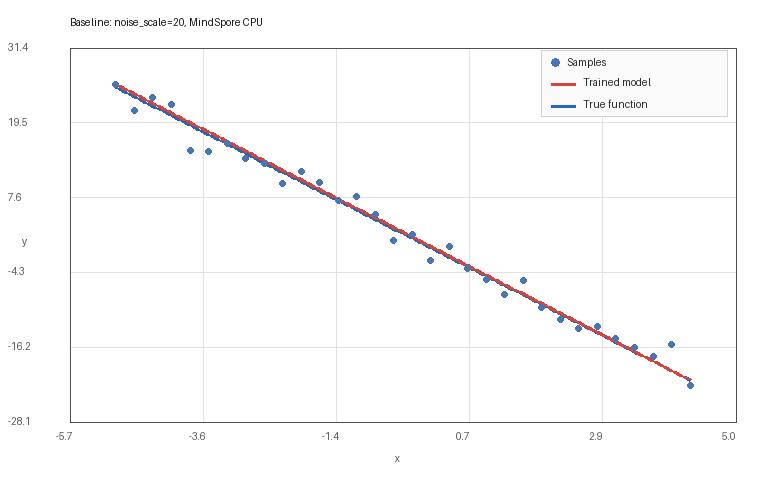

Saved baseline visualization to baseline_linear_fit.png


In [10]:
from IPython.display import Image as IPythonImage, display

def make_fit_plot_image(x, y, trained_w, trained_b, title, width=760, height=480):
    x = np.asarray(x, dtype=np.float32).reshape(-1)
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    line_x = np.linspace(float(x.min()), float(x.max()), 120)
    trained_y = trained_w * line_x + trained_b
    true_y = -5 * line_x + 0.1

    all_x = np.concatenate([x, line_x])
    all_y = np.concatenate([y, trained_y, true_y])
    x_min, x_max = float(all_x.min()), float(all_x.max())
    y_min, y_max = float(all_y.min()), float(all_y.max())
    x_pad = (x_max - x_min) * 0.08 or 1.0
    y_pad = (y_max - y_min) * 0.12 or 1.0
    x_min, x_max = x_min - x_pad, x_max + x_pad
    y_min, y_max = y_min - y_pad, y_max + y_pad

    margin_left, margin_top, margin_right, margin_bottom = 70, 48, 24, 58
    plot_w = width - margin_left - margin_right
    plot_h = height - margin_top - margin_bottom

    def px(x_value):
        return margin_left + (x_value - x_min) / (x_max - x_min) * plot_w

    def py(y_value):
        return margin_top + (y_max - y_value) / (y_max - y_min) * plot_h

    img = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(img)
    axis_color = (80, 80, 80)
    grid_color = (226, 226, 226)
    scatter_color = (72, 118, 176)
    trained_color = (214, 68, 60)
    true_color = (43, 102, 181)

    draw.text((margin_left, 16), title, fill=(20, 20, 20))

    for t in np.linspace(x_min, x_max, 6):
        x_pos = px(t)
        draw.line([(x_pos, margin_top), (x_pos, margin_top + plot_h)], fill=grid_color)
        draw.text((x_pos - 14, margin_top + plot_h + 8), f"{t:.1f}", fill=(90, 90, 90))
    for t in np.linspace(y_min, y_max, 6):
        y_pos = py(t)
        draw.line([(margin_left, y_pos), (margin_left + plot_w, y_pos)], fill=grid_color)
        draw.text((8, y_pos - 7), f"{t:.1f}", fill=(90, 90, 90))

    draw.rectangle(
        [margin_left, margin_top, margin_left + plot_w, margin_top + plot_h],
        outline=axis_color,
    )
    draw.text((margin_left + plot_w // 2 - 8, height - 28), "x", fill=axis_color)
    draw.text((22, margin_top + plot_h // 2), "y", fill=axis_color)

    true_points = [(px(a), py(b)) for a, b in zip(line_x, true_y)]
    trained_points = [(px(a), py(b)) for a, b in zip(line_x, trained_y)]
    draw.line(true_points, fill=true_color, width=3)
    draw.line(trained_points, fill=trained_color, width=3)

    for a, b in zip(x, y):
        cx, cy = px(a), py(b)
        draw.ellipse([cx - 3, cy - 3, cx + 3, cy + 3], fill=scatter_color)

    legend_x = margin_left + plot_w - 185
    legend_y = margin_top + 10
    draw.rectangle(
        [legend_x - 10, legend_y - 8, legend_x + 176, legend_y + 58],
        fill=(250, 250, 250),
        outline=(210, 210, 210),
    )
    draw.ellipse([legend_x, legend_y, legend_x + 8, legend_y + 8], fill=scatter_color)
    draw.text((legend_x + 16, legend_y - 2), "Samples", fill=(40, 40, 40))
    draw.line([(legend_x, legend_y + 26), (legend_x + 24, legend_y + 26)], fill=trained_color, width=3)
    draw.text((legend_x + 32, legend_y + 18), "Trained model", fill=(40, 40, 40))
    draw.line([(legend_x, legend_y + 48), (legend_x + 24, legend_y + 48)], fill=true_color, width=3)
    draw.text((legend_x + 32, legend_y + 40), "True function", fill=(40, 40, 40))

    return img

x = data._data.reshape((-1, 1))
y = data._label.reshape((-1, 1))
baseline_image = make_fit_plot_image(
    x,
    y,
    w,
    b,
    "Baseline: noise_scale=20, MindSpore CPU",
)
baseline_image.save("baseline_linear_fit.png")
display(IPythonImage(filename="baseline_linear_fit.png"))
print("Saved baseline visualization to baseline_linear_fit.png")


## 8、不同噪声强度对比实验

为了满足报告中“实验数据、数据分析”的要求，在保持线性模型结构不变的前提下，改变模拟数据中的噪声强度，比较低噪声、原始噪声和高噪声下的拟合效果。

对比设置：

- `noise_scale=5`：低噪声数据；
- `noise_scale=20`：老师模板中的原始设置；
- `noise_scale=50`：高噪声数据。


In [11]:
noise_levels = [5.0, 20.0, 50.0]
prediction_points = [-10, -5, 0, 5, 10]
noise_experiment_results = []

def run_noise_experiment(noise_scale, seed=42, epochs=20, learning_rate=0.01):
    np.random.seed(seed)
    ms.set_seed(seed)
    exp_data = Iterable(noise_scale=noise_scale, seed=seed)
    exp_dataset = GeneratorDataset(source=exp_data, column_names=["data", "label"])
    exp_net = nn.Dense(1, 1)
    exp_loss_fn = nn.MSELoss()
    exp_opt = nn.SGD(exp_net.trainable_params(), learning_rate=learning_rate)

    final_loss = None
    for _ in range(epochs):
        final_loss = train_loop(exp_net, exp_dataset, exp_loss_fn, exp_opt, verbose=False)

    wb = [x.asnumpy() for x in exp_net.trainable_params()]
    learned_w, learned_b = float(np.squeeze(wb[0])), float(np.squeeze(wb[1]))
    predictions = {
        point: float(exp_net(ms.Tensor([[point]], ms.float32)).asnumpy().squeeze())
        for point in prediction_points
    }
    return {
        "noise_scale": noise_scale,
        "final_loss": final_loss,
        "w": learned_w,
        "b": learned_b,
        "w_error": abs(learned_w - (-5.0)),
        "predictions": predictions,
        "x": exp_data._data.reshape((-1, 1)),
        "y": exp_data._label.reshape((-1, 1)),
    }

for noise_scale in noise_levels:
    result = run_noise_experiment(noise_scale)
    noise_experiment_results.append(result)

headers = ["noise_scale", "final_loss", "w", "b", "w_error"] + [f"pred_x={p}" for p in prediction_points]
rows = []
for result in noise_experiment_results:
    row = [
        result["noise_scale"],
        result["final_loss"],
        result["w"],
        result["b"],
        result["w_error"],
    ] + [result["predictions"][p] for p in prediction_points]
    rows.append(row)

print(" | ".join(f"{h:>12}" for h in headers))
print("-" * (15 * len(headers)))
for row in rows:
    print(" | ".join(f"{v:12.6f}" for v in row))


 noise_scale |   final_loss |            w |            b |      w_error |   pred_x=-10 |    pred_x=-5 |     pred_x=0 |     pred_x=5 |    pred_x=10
------------------------------------------------------------------------------------------------------------------------------------------------------
    5.000000 |     0.093336 |    -5.013101 |     0.084885 |     0.013101 |    50.215889 |    25.150387 |     0.084885 |   -24.980618 |   -50.046120
   20.000000 |     1.493384 |    -5.052402 |     0.339533 |     0.052402 |    50.863556 |    25.601545 |     0.339533 |   -24.922480 |   -50.184494
   50.000000 |     9.333697 |    -5.131005 |     0.848828 |     0.131005 |    52.158878 |    26.503853 |     0.848828 |   -24.806198 |   -50.461224


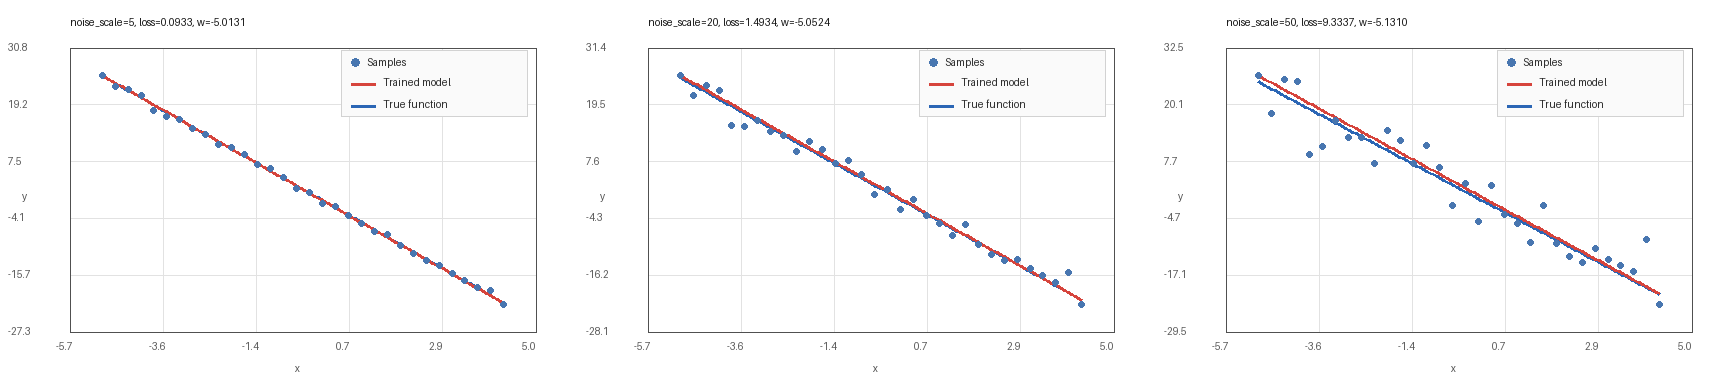

Saved noise comparison visualization to noise_scale_comparison.png


In [12]:
panel_images = []
for result in noise_experiment_results:
    title = (
        f"noise_scale={result['noise_scale']:.0f}, "
        f"loss={result['final_loss']:.4f}, w={result['w']:.4f}"
    )
    panel_images.append(
        make_fit_plot_image(
            result["x"],
            result["y"],
            result["w"],
            result["b"],
            title,
            width=560,
            height=390,
        )
    )

gap = 18
comparison_image = Image.new(
    "RGB",
    (sum(img.width for img in panel_images) + gap * (len(panel_images) - 1), panel_images[0].height),
    "white",
)
x_offset = 0
for img in panel_images:
    comparison_image.paste(img, (x_offset, 0))
    x_offset += img.width + gap

comparison_image.save("noise_scale_comparison.png")
display(IPythonImage(filename="noise_scale_comparison.png"))
print("Saved noise comparison visualization to noise_scale_comparison.png")


### 对比实验现象

固定模型结构和训练参数后，噪声强度越大，样本点围绕真实直线的离散程度越高，最终损失通常也越大。尽管高噪声会增加参数波动，三组实验学到的斜率仍应接近真实斜率 `-5`，说明简单线性模型能够学习数据中的主要线性趋势。


## 9、不同网络结构对比实验

在老师模板的 baseline 数据集（`noise_scale=20`）上，对比简单线性模型 `nn.Dense(1, 1)` 与一层隐藏层 MLP `1-8-ReLU-1` 的拟合效果。由于 MLP 参数更多、优化难度更高，线性模型保留指导书训练设置，MLP 使用 Adam 优化器并增加训练轮次，使其能够充分学习负线性斜率。


In [13]:
structure_experiment_results = []
prediction_points = [-10, -5, 0, 5, 10]

def dataset_mse(model, exp_data):
    x_tensor = ms.Tensor(exp_data._data.astype(np.float32), ms.float32)
    y_true = exp_data._label.astype(np.float32)
    y_pred = model(x_tensor).asnumpy()
    return float(np.mean((y_pred - y_true) ** 2))

def train_and_evaluate_structure(
    model_name,
    model,
    optimizer_factory,
    seed=42,
    epochs=20,
    learning_rate=0.01,
):
    np.random.seed(seed)
    ms.set_seed(seed)
    exp_data = Iterable(noise_scale=20.0, seed=seed)
    exp_dataset = GeneratorDataset(source=exp_data, column_names=["data", "label"])
    exp_loss_fn = nn.MSELoss()
    exp_opt = optimizer_factory(model.trainable_params(), learning_rate)

    final_loss = None
    for _ in range(epochs):
        final_loss = train_loop(model, exp_dataset, exp_loss_fn, exp_opt, verbose=False)

    predictions = {
        point: float(model(ms.Tensor([[point]], ms.float32)).asnumpy().squeeze())
        for point in prediction_points
    }
    x_line = np.linspace(float(exp_data._data.min()), float(exp_data._data.max()), 120).reshape((-1, 1)).astype(np.float32)
    y_line = model(ms.Tensor(x_line, ms.float32)).asnumpy().reshape(-1)
    return {
        "model": model_name,
        "epochs": epochs,
        "optimizer": optimizer_factory.__name__,
        "final_loss": final_loss,
        "train_mse": dataset_mse(model, exp_data),
        "predictions": predictions,
        "x": exp_data._data.reshape((-1, 1)),
        "y": exp_data._label.reshape((-1, 1)),
        "line_x": x_line.reshape(-1),
        "line_y": y_line,
    }

def make_sgd(params, learning_rate):
    return nn.SGD(params, learning_rate=learning_rate)

def make_adam(params, learning_rate):
    return nn.Adam(params, learning_rate=learning_rate)

linear_model = nn.Dense(1, 1)
mlp_model = nn.SequentialCell([
    nn.Dense(1, 8),
    nn.ReLU(),
    nn.Dense(8, 1),
])

structure_experiment_results.append(
    train_and_evaluate_structure(
        "Linear Dense(1,1)",
        linear_model,
        make_sgd,
        epochs=20,
        learning_rate=0.01,
    )
)
structure_experiment_results.append(
    train_and_evaluate_structure(
        "MLP 1-8-ReLU-1",
        mlp_model,
        make_adam,
        epochs=500,
        learning_rate=0.01,
    )
)

headers = ["model", "optimizer", "epochs", "final_loss", "train_mse"] + [f"pred_x={p}" for p in prediction_points]
print(" | ".join(f"{h:>18}" for h in headers))
print("-" * (21 * len(headers)))
for result in structure_experiment_results:
    row = [
        result["epochs"],
        result["final_loss"],
        result["train_mse"],
    ] + [result["predictions"][p] for p in prediction_points]
    print(
        f"{result['model']:>18} | {result['optimizer']:>18} | "
        + " | ".join(f"{v:18.6f}" for v in row)
    )


             model |          optimizer |             epochs |         final_loss |          train_mse |         pred_x=-10 |          pred_x=-5 |           pred_x=0 |           pred_x=5 |          pred_x=10
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 Linear Dense(1,1) |           make_sgd |          20.000000 |           1.493401 |           2.952100 |          50.863548 |          25.601540 |           0.339529 |         -24.922482 |         -50.184494
    MLP 1-8-ReLU-1 |          make_adam |         500.000000 |           1.043528 |           2.398825 |          47.604061 |          24.381939 |          -0.383600 |         -23.632921 |         -46.121098


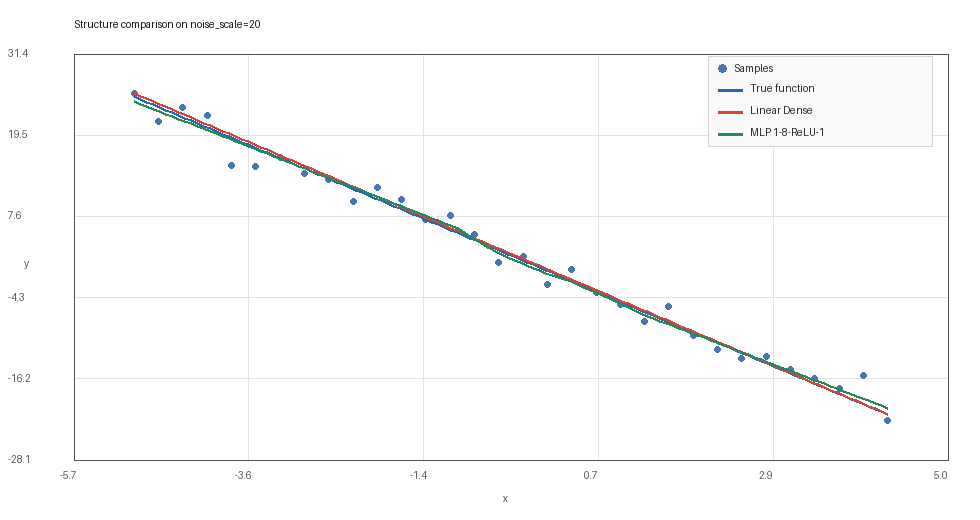

Saved structure comparison visualization to mlp_structure_comparison.png


In [14]:
def make_structure_comparison_image(results, width=980, height=520):
    x = results[0]["x"].reshape(-1)
    y = results[0]["y"].reshape(-1)
    line_x = results[0]["line_x"]
    true_y = -5 * line_x + 0.1
    all_y = [y, true_y] + [r["line_y"] for r in results]
    all_x = np.concatenate([x, line_x])
    all_y = np.concatenate(all_y)

    x_min, x_max = float(all_x.min()), float(all_x.max())
    y_min, y_max = float(all_y.min()), float(all_y.max())
    x_pad = (x_max - x_min) * 0.08 or 1.0
    y_pad = (y_max - y_min) * 0.12 or 1.0
    x_min, x_max = x_min - x_pad, x_max + x_pad
    y_min, y_max = y_min - y_pad, y_max + y_pad

    margin_left, margin_top, margin_right, margin_bottom = 74, 54, 32, 60
    plot_w = width - margin_left - margin_right
    plot_h = height - margin_top - margin_bottom

    def px(x_value):
        return margin_left + (x_value - x_min) / (x_max - x_min) * plot_w

    def py(y_value):
        return margin_top + (y_max - y_value) / (y_max - y_min) * plot_h

    img = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(img)
    axis_color = (80, 80, 80)
    grid_color = (226, 226, 226)
    sample_color = (72, 118, 176)
    true_color = (43, 102, 181)
    linear_color = (214, 68, 60)
    mlp_color = (35, 140, 95)

    draw.text((margin_left, 18), "Structure comparison on noise_scale=20", fill=(20, 20, 20))
    for t in np.linspace(x_min, x_max, 6):
        x_pos = px(t)
        draw.line([(x_pos, margin_top), (x_pos, margin_top + plot_h)], fill=grid_color)
        draw.text((x_pos - 14, margin_top + plot_h + 9), f"{t:.1f}", fill=(90, 90, 90))
    for t in np.linspace(y_min, y_max, 6):
        y_pos = py(t)
        draw.line([(margin_left, y_pos), (margin_left + plot_w, y_pos)], fill=grid_color)
        draw.text((8, y_pos - 7), f"{t:.1f}", fill=(90, 90, 90))

    draw.rectangle(
        [margin_left, margin_top, margin_left + plot_w, margin_top + plot_h],
        outline=axis_color,
    )
    draw.text((margin_left + plot_w // 2 - 8, height - 28), "x", fill=axis_color)
    draw.text((24, margin_top + plot_h // 2), "y", fill=axis_color)

    for a, b in zip(x, y):
        cx, cy = px(a), py(b)
        draw.ellipse([cx - 3, cy - 3, cx + 3, cy + 3], fill=sample_color)

    draw.line([(px(a), py(b)) for a, b in zip(line_x, true_y)], fill=true_color, width=3)
    colors = [linear_color, mlp_color]
    for result, color in zip(results, colors):
        draw.line([(px(a), py(b)) for a, b in zip(result["line_x"], result["line_y"])], fill=color, width=3)

    legend_x = margin_left + plot_w - 230
    legend_y = margin_top + 10
    draw.rectangle([legend_x - 10, legend_y - 8, legend_x + 214, legend_y + 82], fill=(250, 250, 250), outline=(210, 210, 210))
    draw.ellipse([legend_x, legend_y, legend_x + 8, legend_y + 8], fill=sample_color)
    draw.text((legend_x + 16, legend_y - 2), "Samples", fill=(40, 40, 40))
    draw.line([(legend_x, legend_y + 26), (legend_x + 24, legend_y + 26)], fill=true_color, width=3)
    draw.text((legend_x + 32, legend_y + 18), "True function", fill=(40, 40, 40))
    draw.line([(legend_x, legend_y + 48), (legend_x + 24, legend_y + 48)], fill=linear_color, width=3)
    draw.text((legend_x + 32, legend_y + 40), "Linear Dense", fill=(40, 40, 40))
    draw.line([(legend_x, legend_y + 70), (legend_x + 24, legend_y + 70)], fill=mlp_color, width=3)
    draw.text((legend_x + 32, legend_y + 62), "MLP 1-8-ReLU-1", fill=(40, 40, 40))
    return img

structure_image = make_structure_comparison_image(structure_experiment_results)
structure_image.save("mlp_structure_comparison.png")
display(IPythonImage(filename="mlp_structure_comparison.png"))
print("Saved structure comparison visualization to mlp_structure_comparison.png")


### 网络结构对比现象

在同一 baseline 数据集上比较线性模型与优化后的 MLP 后，可以观察两者都能学习到整体负线性趋势。线性模型结构与线性数据规律直接匹配，因此在较少训练轮次下就能稳定拟合；MLP 通过 Adam 优化器和更多训练轮次后也能明显拟合下降趋势，但在训练设置、外推稳定性和解释性上比简单线性模型更敏感。
